# Freight Rate Prediction

## 0. Setup
Imports, file paths, and random seed for reproducibility.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
SEED = 42
DATA_DIR = 'data/'
train_test_file = 'train_test.csv'
dec_chart_file = 'december_chart_inputs.csv'
val_file = 'validation.csv'
val_template_file = 'validation_predictions_template.csv'

In [4]:
df_train_test = pd.read_csv(DATA_DIR+train_test_file, parse_dates=['date'])
df_train_test.head(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [5]:
df_val = pd.read_csv(DATA_DIR+val_file, parse_dates=['date'])
df_val.head(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [6]:
df_dec_chart = pd.read_csv(DATA_DIR+dec_chart_file, parse_dates=['date'])
df_dec_chart.head(5)

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


In [7]:
df_val_template = pd.read_csv(DATA_DIR+val_template_file)
df_val_template.head(5)

,load_id,predicted_rate
0,TE-000001,NaN
1,TE-000002,NaN
2,TE-000003,NaN
3,TE-000004,NaN
4,TE-000005,NaN


## 1. Data Overview
Load the three datasets and check shape, columns, date ranges, missing values, duplicates, and category coverage.


In [8]:
# Section 1 setup: all datasets in one place
datasets = {
    'train_test': df_train_test,
    'validation': df_val,
    'december_chart': df_dec_chart,
    'val_template': df_val_template,
}

### 1.1 Shape and data types

In [9]:
shape_rows = []
for name, df in datasets.items():
    shape_rows.append({'dataset': name, 'rows': df.shape[0], 'columns': df.shape[1]})

pd.DataFrame(shape_rows)

,dataset,rows,columns
0,train_test,48000,14
1,validation,12000,13
2,december_chart,31,7
3,val_template,12000,2


In [10]:
# Data types side by side (NaN = column not present in that dataset)
pd.DataFrame({name: df.dtypes for name, df in datasets.items()})

,train_test,validation,december_chart,val_template
date,datetime64[us],datetime64[us],datetime64[us],NaN
delivery,str,str,str,NaN
delivery_lat,float64,float64,NaN,NaN
delivery_lon,float64,float64,NaN,NaN
distance,float64,float64,int64,NaN
equipment,str,str,str,NaN
load_id,str,str,NaN,str
market_index,float64,float64,NaN,NaN
pickup,str,str,str,NaN
pickup_lat,float64,float64,NaN,NaN


In [11]:
print('In train, not in validation:', set(df_train_test.columns) - set(df_val.columns))
print('In train, not in December:  ', set(df_train_test.columns) - set(df_dec_chart.columns))

In train, not in validation: {'posted_rate'}
In train, not in December:   {'market_index', 'pickup_lat', 'delivery_lon', 'pickup_lon', 'delivery_lat', 'quote_signal', 'posted_rate', 'load_id'}


### 1.2 Date ranges

In [12]:
date_rows = []
for name, df in datasets.items():
    if 'date' in df.columns:
        date_rows.append({
            'dataset': name,
            'min_date': df['date'].min(),
            'max_date': df['date'].max(),
        })

pd.DataFrame(date_rows)

,dataset,min_date,max_date
0,train_test,2025-01-01,2025-10-31
1,validation,2025-11-01,2025-12-31
2,december_chart,2025-12-01,2025-12-31


### 1.3 Missing values

In [13]:
missing_cols = {}
for name, df in datasets.items():
    nulls = df.isnull().sum()
    missing_cols[name] = nulls[nulls > 0]

pd.DataFrame(missing_cols)

,train_test,validation,december_chart,val_template
market_index,374.0,249.0,NaN,NaN
predicted_rate,NaN,NaN,31.0,12000.0
weight,300.0,165.0,NaN,NaN


### 1.4 Duplicates

In [14]:
df_train_test.duplicated().sum()

np.int64(0)

In [15]:
dups_cols = {}
for name, df in datasets.items():
    cols = set(df.columns) - set(['load_id'])
    dups = df.duplicated(cols).sum()
    dups_cols[name] = dups

pd.Series(dups_cols)

train_test            0
validation            0
december_chart        0
val_template      11999
dtype: int64

### 1.5 Categories and coverage

In [16]:
categories = {}
coverage = {}
for name, df in datasets.items():
    categories[name] = df.nunique()

pd.DataFrame(categories)

,train_test,validation,december_chart,val_template
date,304.0,61.0,31.0,NaN
delivery,64.0,72.0,1.0,NaN
delivery_lat,64.0,72.0,NaN,NaN
delivery_lon,63.0,71.0,NaN,NaN
distance,21204.0,9309.0,1.0,NaN
equipment,3.0,3.0,1.0,NaN
load_id,48000.0,12000.0,NaN,12000.0
market_index,32884.0,9520.0,NaN,NaN
pickup,64.0,72.0,1.0,NaN
pickup_lat,64.0,72.0,NaN,NaN


In [17]:
#Coverage shows which cities and lanes in validation and December never appear in train, meaning the model has no history for them
def get_values(df, col):
    """Return a column, or build the lane (pickup -> delivery) on the fly."""
    if col == 'lane':
        return df['pickup'] + ' -> ' + df['delivery']
    return df[col]

coverage_rows = []
for name in ['validation', 'december_chart']:
    df = datasets[name]
    for col in ['pickup', 'delivery', 'equipment', 'lane']:
        train_values = set(get_values(df_train_test, col).unique())
        target_values = get_values(df, col)
        unseen = set(target_values.unique()) - train_values

        coverage_rows.append({
            'dataset': name,
            'column': col,
            'unseen_values': len(unseen),
        })

pd.DataFrame(coverage_rows)

,dataset,column,unseen_values
0,validation,pickup,8
1,validation,delivery,8
2,validation,equipment,0
3,validation,lane,736
4,december_chart,pickup,0
5,december_chart,delivery,0
6,december_chart,equipment,0
7,december_chart,lane,0


### 1.6 Descriptive statistics

In [18]:
df_train_test.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,48000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,2025-05-31 19:53:29.399999,1.083387,2.062468,2373.980682
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,2025-01-01 00:00:00,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,2025-03-18 00:00:00,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,2025-05-31 00:00:00,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,2025-08-15 00:00:00,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,2025-10-31 00:00:00,1.467780,3.610350,25533.000000
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,NaN,0.168091,0.291391,1486.493245


In [19]:
df_val.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,11835.000000,12000,11751.000000,12000.000000
mean,35.574216,-90.724880,35.609538,-90.913530,1141.773100,30506.636248,2025-12-01 02:30:28.800000,0.926913,2.051334
min,25.500000,-121.698490,25.500000,-121.698490,70.000000,-47500.000000,2025-11-01 00:00:00,0.723610,1.234760
25%,31.986910,-97.226810,32.009290,-98.400590,556.100000,25493.000000,2025-11-16 00:00:00,0.863880,1.903467
50%,35.294790,-87.528710,35.294790,-87.528710,953.600000,31193.000000,2025-12-01 00:00:00,0.922900,2.051230
75%,39.411040,-82.783790,39.411040,-82.783790,1670.500000,36843.500000,2025-12-16 00:00:00,0.992355,2.200030
max,44.302960,-69.500000,44.302960,-69.500000,3325.700000,47500.000000,2025-12-31 00:00:00,1.098950,2.896350
std,4.366999,13.411638,4.351844,13.624744,732.333797,10572.590450,NaN,0.074109,0.219804


## 2. Exploratory Data Analysis
Distributions of the target and key features, relationships between rate and distance, equipment, lanes, and time.


### 2.1 Target distribution

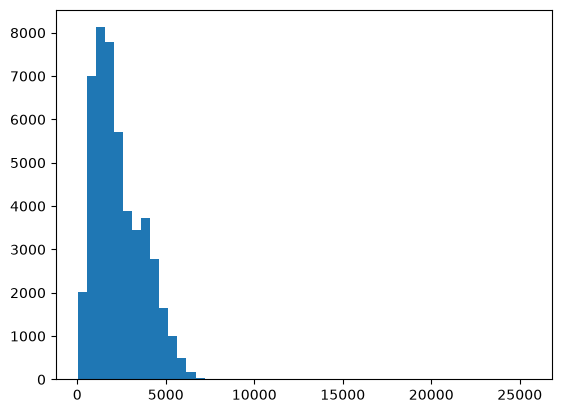

In [20]:
plt.hist(df_train_test['posted_rate'], bins=50);

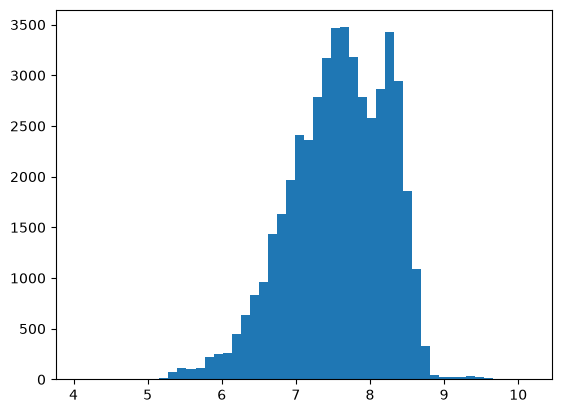

In [21]:
plt.hist(np.log1p(df_train_test['posted_rate']), bins=50);

Target is right-skewed with a long tail; log scale shows two modes and isolated extremes on both ends

### 2.2 Rate vs distance

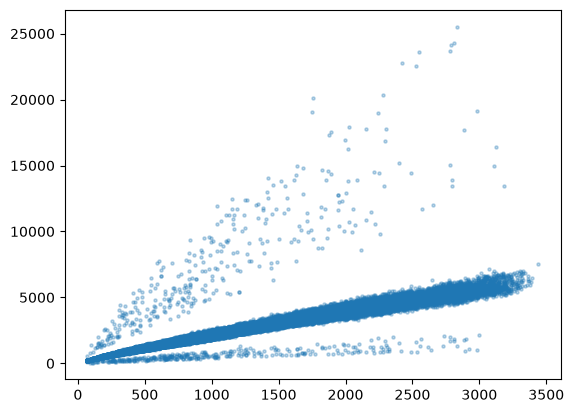

In [22]:
plt.scatter(df_train_test['distance'], df_train_test['posted_rate'], s=5, alpha=0.3)
plt.show()

Rate is roughly linear in distance. Two anomalous groups: a lower band (likely a systematic recording error) and scattered high outliers

### 2.3 Rate by equipment

In [ ]:
df_train_test['rate_per_mile'] = df_train_test['posted_rate']/df_train_test['distance']

<StringArray>
['Dry Van', 'Reefer', 'Flatbed']
Length: 3, dtype: str

<Axes: title={'center': 'rate_per_mile'}, xlabel='equipment'>

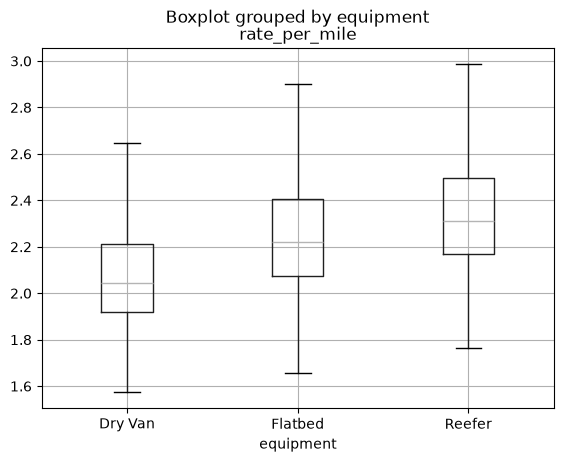

In [58]:
df_train_test.boxplot(column = 'rate_per_mile', by='equipment', showfliers=False)

Reefer has the highest median rate per mile, followed by Flatbed and Dry Van. The difference is around 0.25 $/mile, which adds up on long loads, so equipment is a useful feature. Outliers are hidden here to make the comparison readable.

In [59]:
bins = [0, 1, 1.5, 3.5, 4, 100]
labels = ['0-1', '1-1.5', '1.5-3.5', '3.5-4', '4+']
pd.cut(df_train_test['rate_per_mile'], bins=bins, labels=labels).value_counts().sort_index()

rate_per_mile
0-1          329
1-1.5          8
1.5-3.5    47321
3.5-4          2
4+           340
Name: count, dtype: int64

Almost no loads fall between 1–1.5 or 3.5–4 $/mile (10 in total), so the 669 loads below 1 or above 4 are isolated from the normal range. These are treated as recording errors in the cleaning step.

### 2.4 Rate over time

<Axes: xlabel='date'>

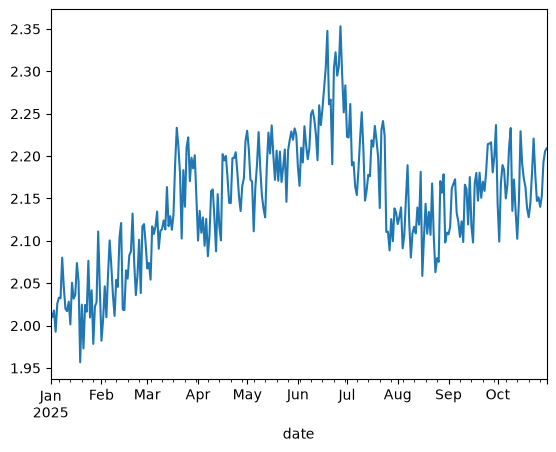

In [34]:
df_train_test.groupby('date')['rate_per_mile'].median().plot()

Rate per mile rises from January to a late-June peak, drops in July, then stabilizes. Short-term oscillation suggests a day-of-week effect.

### 2.5 Quote signal vs actual rate per mile

[]

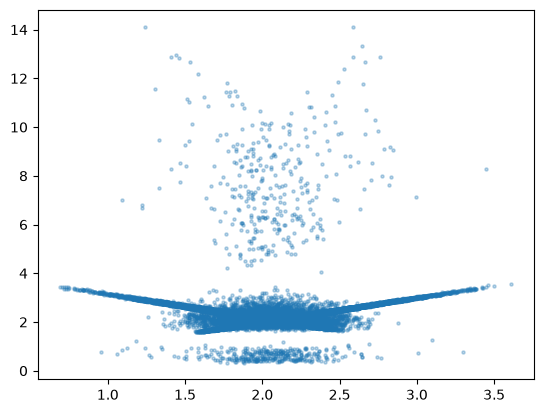

In [37]:
plt.scatter(df_train_test['quote_signal'], df_train_test['rate_per_mile'], s=5, alpha=0.3)
plt.plot()

The relationship between quote signal and rate per mile is V-shaped. Above ~2.5, rate rises with the quote as expected. Below ~1.6, rate rises as the quote falls, which is the opposite of how a price quote should behave. The rate outliers (above 4 and below 1) appear at every quote level, so they come from the rate, not the quote.

In [51]:
left_arm = df_train_test[
    (df_train_test['quote_signal'] < 1.6) &
    (df_train_test['rate_per_mile'] > 1.5) &
    (df_train_test['rate_per_mile'] < 4)
]

(left_arm['quote_signal'] + left_arm['rate_per_mile']).describe()

count    2270.000000
mean        4.119734
std         0.138150
min         3.158420
25%         4.122771
50%         4.144800
75%         4.165046
max         4.562847
dtype: float64

In the left arm (quote < 1.6, normal rates), quote + rate per mile is nearly constant: median 4.14, with the middle 50% between 4.12 and 4.17 across 2,270 rows (~5% of train). This suggests the quote signal is mirrored in this region. A tree-based model can learn this pattern; correcting it explicitly (4.14 − quote) is a possible improvement.

In [54]:
df_train_test['quote_signal'].describe()

count    48000.000000
mean         2.062468
std          0.291391
min          0.692280
25%          1.891030
50%          2.055750
75%          2.221685
max          3.610350
Name: quote_signal, dtype: float64

### 2.6 Key findings

- **Target:** posted rate is right-skewed with a long tail; rate scales roughly linearly with distance, so rate per mile is used as the modeling target.
- **Outliers:** 669 loads have a rate per mile below 1 or above 4, while only 10 fall between 1–1.5 or 3.5–4. These isolated groups point to recording errors.
- **Equipment:** Reefer > Flatbed > Dry Van in median rate per mile, with a difference of around 0.25 $/mile.
- **Time:** rate per mile rises to a late-June peak, drops in July, and stabilizes from August to October, with short-term oscillation suggesting a day-of-week effect. This supports a time-based split.
- **Quote signal:** loosely related to rate in its normal range (~1.6–2.5), so route, equipment and date features are needed; V-shaped overall, with a mirrored region below ~1.6 (quote + rate ≈ 4.14). Favors a non-linear model.

## 3. Data Cleaning
Handle data-quality issues found in sections 1 and 2. Each decision is documented with its rationale.


### 3.1 Negative weights

In [60]:
print('Negative weights in train:', (df_train_test['weight'] < 0).sum())
print('Negative weights in validation:', (df_val['weight'] < 0).sum())

Negative weights in train: 292
Negative weights in validation: 145


In [62]:
print(df_train_test.loc[df_train_test['weight'] < 0, 'weight'].abs().describe())
print()
print(df_train_test.loc[df_train_test['weight'] > 0, 'weight'].describe())

count      292.000000
mean     31724.195205
std       8262.536326
min       5000.000000
25%      25928.500000
50%      31821.500000
75%      37284.250000
max      47500.000000
Name: weight, dtype: float64

count    47408.000000
mean     31415.358674
std       7994.902979
min       5000.000000
25%      25922.000000
50%      31493.500000
75%      37063.000000
max      47500.000000
Name: weight, dtype: float64


In [ ]:
for df in [df_train_test, df_val]:
    df['weight'] = df['weight'].abs()

In [65]:
print('Negative weights in train:', (df_train_test['weight'] < 0).sum())
print('Negative weights in validation:', (df_val['weight'] < 0).sum())

Negative weights in train: 0
Negative weights in validation: 0


292 train and 145 validation loads have negative weights. Their absolute values follow the same distribution as the positive weights (median ~31.8k vs ~31.5k, same min and max), so this is a sign error. Fixed by taking the absolute value.

### 3.2 Missing values

In [67]:
print(df_train_test[['weight', 'market_index']].isna().sum())
print(df_val[['weight', 'market_index']].isna().sum())

weight          300
market_index    374
dtype: int64
weight          165
market_index    249
dtype: int64


In [68]:
for df in [df_train_test, df_val]:
    df['weight_missing'] = df['weight'].isna().astype(int)
    df['market_index_missing'] = df['market_index'].isna().astype(int)

Weight is missing for 300 train and 165 validation loads, and market_index for 374 and 249. Rows can’t be dropped from validation, so missing indicators are added here. Values will be filled with the training-set median after the split, to avoid leakage.

### 3.3 Extreme rates

In [70]:
rows_before = len(df_train_test)

df_train_test = df_train_test[
    (df_train_test['rate_per_mile'] >= 1) &
    (df_train_test['rate_per_mile'] <= 4)
]

print('Rows removed:', rows_before - len(df_train_test))
print('Rows remaining:', len(df_train_test))

Rows removed: 669
Rows remaining: 47331


### 3.4 Data types alignment

In [72]:
print(df_dec_chart.dtypes)
df_dec_chart['distance'] = df_dec_chart['distance'].astype(float)
df_dec_chart['weight'] = df_dec_chart['weight'].astype(float)
print(df_dec_chart.dtypes)

pickup                       str
delivery                     str
distance                   int64
equipment                    str
weight                     int64
date              datetime64[us]
predicted_rate           float64
dtype: object
pickup                       str
delivery                     str
distance                 float64
equipment                    str
weight                   float64
date              datetime64[us]
predicted_rate           float64
dtype: object


In the December file, distance and weight are stored as integers, while train and validation use floats. They are cast to float for consistency across datasets.

## 4. Train/Test Split
Time-based split that mirrors the validation scenario: train on earlier months, test on the most recent ones.


In [73]:
split_date = '2025-09-01'

train = df_train_test[df_train_test['date']<split_date]
test = df_train_test[df_train_test['date']>split_date]

print('Train:', train.shape, train['date'].min().date(), 'to', train['date'].max().date())
print('Test: ', test.shape, test['date'].min().date(), 'to', test['date'].max().date())

Train: (37951, 17) 2025-01-01 to 2025-08-31
Test:  (9224, 17) 2025-09-02 to 2025-10-31


In [ ]:
weight_median = train['weight'].median()
market_index_median = train['market_index'].median()

for df in [train, test, df_val]:
    print('Before:')
    print(df[['weight', 'market_index']].isna().sum())
    df['weight']=df['weight'].fillna(weight_median)
    df['market_index'] = df['market_index'].fillna(market_index_median)
    print('After:')
    print(df[['weight', 'market_index']].isna().sum())


Validation contains future loads (November–December), so the split mirrors that: January–August for training and September–October for testing. A random split would mix months and give an overly optimistic evaluation.

## 5. Feature Engineering
Date features, lane features, and target transformation. Statistics that learn from data are fitted on the training set only.


### 5.1 Target: rate per mile

### 5.2 Date features

### 5.3 Lane features

### 5.4 Feature sets for Model A and Model B

## 6. Baselines
Simple non-ML references to beat, such as the quote signal multiplied by distance.


### 6.1 Quote signal baseline

### 6.2 Lane median baseline

## 7. Model Comparison
Model A (all features) vs Model B (December-compatible features), compared against the baselines.


### 7.1 Model A: all features

### 7.2 Model B: December-compatible features

### 7.3 Results and model selection

## 8. Final Evaluation
One-time evaluation of the selected model on the held-out test set.


## 9. Final Training and Predictions
Retrain on all development data and generate predictions for validation and December.


### 9.1 Retrain on full development data

### 9.2 Validation predictions

### 9.3 December predictions

## 10. Scoring and December Chart
Run score.py and interpret the December chart.


## 11. Conclusions
Key findings, limitations, and next steps with more time.